In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
data = pd.read_csv("ecg.csv", header=None)

print(data.head())

        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138       139  140  
0  0.2577

In [3]:
X = data.iloc[:,:-1].values
y = data.iloc[:,-1].values

print(X.shape)
print(y.shape)
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)
#imp
Normal_label = 0

X_train_normal = X_train[y_train==Normal_label]

X_fit,X_val = train_test_split(
    X_train_normal,test_size=0.2,random_state=42
)

(4998, 140)
(4998,)


In [12]:
scaler = StandardScaler()

X_fit = scaler.fit_transform(X_fit)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_fit = X_fit.reshape(-1,140,1)
X_val = X_val.reshape(-1,140,1)
X_test = X_test.reshape(-1,140,1)


model = keras.Sequential([
    keras.Input(shape=(140,1)),

    keras.layers.Conv1D(32,3,activation="relu", padding="same"),
    keras.layers.MaxPooling1D(2,padding="same"),

    keras.layers.Conv1D(16,3,activation="relu", padding="same"),
    keras.layers.MaxPooling1D(2, padding="same"),

    keras.layers.Conv1D(16, 3, activation="relu", padding="same"),
    keras.layers.UpSampling1D(2),

    keras.layers.Conv1D(16, 3, activation="relu", padding="same"),
    keras.layers.UpSampling1D(2),

    
    keras.layers.Conv1D(1, 3, activation="linear", padding="same")

    
])

model.summary()

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 140, 32)             │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 70, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 70, 16)              │           1,552 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 35, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 35, 16)              │             784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d (UpSampling1D)         │ (None, 70, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 70, 16)              │             784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d_1 (UpSampling1D)       │ (None, 140, 16)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 140, 1)              │              49 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,297 (12.88 KB)

 Trainable params: 3,297 (12.88 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    X_fit,X_fit,
    epochs=10,
    batch_size=32,
    validation_data=(X_val,X_val)
)

Epoch 1/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.3452 - mae: 0.3518 - val_loss: 0.0836 - val_mae: 0.1892
Epoch 2/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0648 - mae: 0.1617 - val_loss: 0.0482 - val_mae: 0.1402
Epoch 3/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0469 - mae: 0.1357 - val_loss: 0.0404 - val_mae: 0.1279
Epoch 4/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0399 - mae: 0.1258 - val_loss: 0.0352 - val_mae: 0.1201
Epoch 5/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0350 - mae: 0.1188 - val_loss: 0.0310 - val_mae: 0.1138
Epoch 6/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0311 - mae: 0.1131 - val_loss: 0.0278 - val_mae: 0.1088
Epoch 7/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0280 - mae: 0.1084 - val_loss: 0.0257 - val_mae: 0.1066
Epoch 8/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0256 - mae: 0.1050 - val_loss: 0.0234 - val_mae: 0.1015
Epoch 9/10
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0235 - mae:

In [14]:
val_predictions = model.predict(X_val)

val_errors = np.mean(
    np.square(X_val-val_predictions),axis=(1,2)
)

threshold = np.percentile(val_errors,99)
print("Threshold:", threshold)

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step 
Threshold: 0.08394262430614374


In [16]:
predictions = model.predict(X_test)
errors = np.mean(
    np.square(X_test-predictions),axis=(1,2)
)

y_pred = (errors>threshold).astype(int)

y_actual = (y_test != Normal_label).astype(int)

print("Predictions:", y_pred[:20])


# 12. Evaluate model
print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

print("\nClassification Report:")
print(classification_report(y_actual, y_pred, zero_division=0))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Confusion Matrix:
[[407   9]
 [541  43]]

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.98      0.60       416
           1       0.83      0.07      0.14       584

    accuracy                           0.45      1000
   macro avg       0.63      0.53      0.37      1000
weighted avg       0.66      0.45      0.33      1000



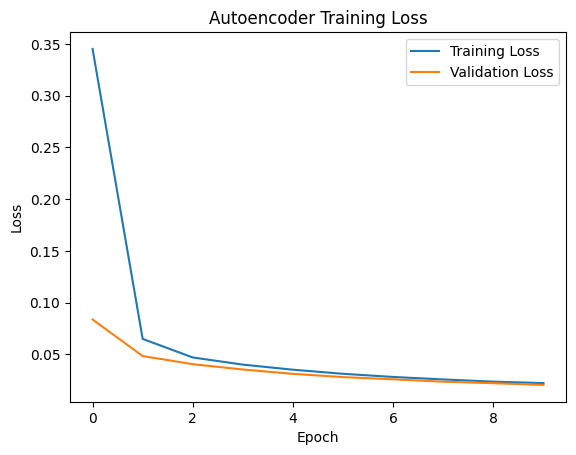

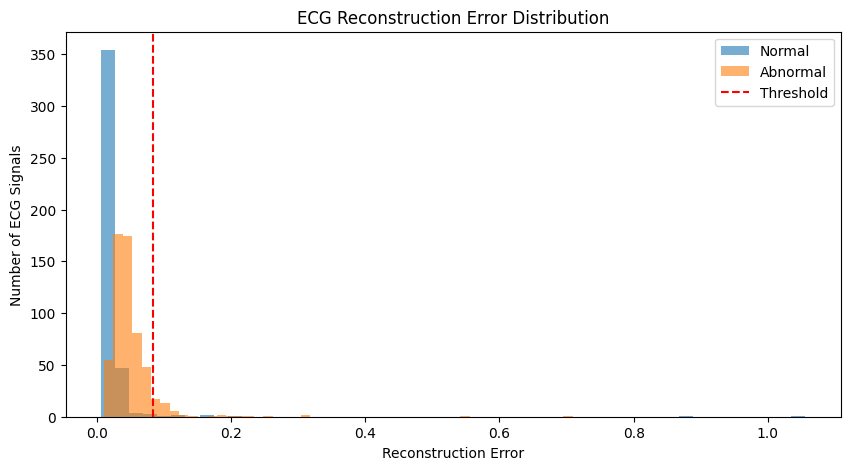

In [17]:
# 13. Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


# 14. Plot reconstruction errors
plt.figure(figsize=(10,5))

plt.hist(errors[y_actual == 0], bins=50,
         alpha=0.6, label="Normal")

plt.hist(errors[y_actual == 1], bins=50,
         alpha=0.6, label="Abnormal")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("ECG Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of ECG Signals")
plt.legend()
plt.show()